# IEEE-CIS Fraud Detection: Training-Only EDA

This notebook presents leakage-conscious exploratory analysis for a fraud decisioning portfolio project. Fraud is rare relative to legitimate activity, so class prevalence and ranking-oriented thinking matter. Customer and attacker behavior also change over time, making chronological validation more realistic than random splitting.

**Guardrail:** every target-aware calculation below uses only the oldest chronological training partition. Validation and holdout targets are not inspected.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from fraud_detection.data import (
    load_train_identity,
    load_train_transaction,
    merge_train_data,
    split_data_chronologically,
    validate_training_data,
)
from fraud_detection.evaluation.eda import (
    categorical_cardinality_summary,
    categorical_summary,
    missingness_fraud_associations,
    missingness_summary,
    save_eda_plots,
    summarize_target,
    temporal_daily_summary,
    transaction_amount_summary,
)

pd.set_option("display.max_columns", 20)
plt.style.use("seaborn-v0_8-whitegrid")

Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\Marwan\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


## 1. Data preparation

The raw files remain unchanged. Existing project functions load, left-join, structurally validate, and split the data chronologically.

In [2]:
raw_dir = PROJECT_ROOT / "data" / "raw"
transaction = load_train_transaction(raw_dir)
identity = load_train_identity(raw_dir)
merged = merge_train_data(transaction, identity)
validation_result = validate_training_data(merged)
split = split_data_chronologically(merged)
train = split.train
del transaction, identity, merged

print(f"TRAIN selected for EDA: {len(train):,} rows")
print(f"Validation excluded: {len(split.validation):,} rows")
print(f"Holdout excluded: {len(split.holdout):,} rows")

TRAIN selected for EDA: 413,378 rows
Validation excluded: 88,581 rows
Holdout excluded: 88,581 rows


## 2. Target distribution

In [3]:
target = summarize_target(train)
pd.Series(
    {
        "train_rows": target.row_count,
        "fraud_count": target.fraud_count,
        "legitimate_count": target.non_fraud_count,
        "fraud_percentage": 100 * target.fraud_rate,
    }
)

train_rows          413378.000000
fraud_count          14538.000000
legitimate_count    398840.000000
fraud_percentage         3.516878
dtype: float64

The minority class is only a small share of transactions. This makes raw accuracy an unhelpful framing for later model selection; the modeling notebook uses PR-AUC as its primary metric.

## 3. Transaction amount

In [4]:
amount_summary = transaction_amount_summary(train)
amount_summary.round(3)

,count,mean,median,std,min,max,q01,q25,q75,q95,q99,iqr_outlier_count,iqr_outlier_rate
isFraud,,,,,,,,,,,,,
0,398840,134.203,68.95,238.757,0.251,31937.391,9.950,43.950,125.0,437.0,1104.0,44908,0.113
1,14538,145.641,75.00,216.149,0.292,4191.000,7.296,34.747,171.0,490.0,994.0,1237,0.085


`TransactionAmt` is right-skewed. The reusable plot uses `log(1 + TransactionAmt)` to make class differences visible without deleting or clipping outliers.

## 4. Relative temporal behavior

In [5]:
daily = temporal_daily_summary(train)
window = len(train) // 5
pd.Series(
    {
        "elapsed_days": int(daily["elapsed_day"].max()) + 1,
        "first_20pct_fraud_rate": train.iloc[:window]["isFraud"].mean(),
        "last_20pct_fraud_rate": train.iloc[-window:]["isFraud"].mean(),
    }
)

elapsed_days              120.000000
first_20pct_fraud_rate      0.026864
last_20pct_fraud_rate       0.040617
dtype: float64

`TransactionDT` is treated only as relative elapsed timeâ€”not converted to a calendar date. Any time-derived variables here are analytical and are not production features.

## 5. Interpretable categorical features

In [6]:
categorical_features = [
    "ProductCD",
    "card4",
    "card6",
    "P_emaildomain",
    "R_emaildomain",
    "DeviceType",
    "DeviceInfo",
]
categorical_summaries = [
    categorical_summary(train, feature)
    for feature in categorical_features
    if feature in train.columns
]
pd.DataFrame(
    [
        {"feature": item.feature, "unique": item.unique_count, "missing_rate": item.missing_rate}
        for item in categorical_summaries
    ]
).sort_values("unique", ascending=False)

,feature,unique,missing_rate
6,DeviceInfo,1546,0.778987
4,R_emaildomain,60,0.750734
3,P_emaildomain,59,0.155538
0,ProductCD,5,0.000000
1,card4,4,0.002005
2,card6,4,0.001998
5,DeviceType,2,0.740197


In [7]:
for item in categorical_summaries:
    print(f"\n{item.feature}")
    display(item.category_metrics.head(10).round(4))


ProductCD


,category,transaction_count,fraud_count,fraud_rate
0,W,297911,6191,0.0208
1,C,50006,5588,0.1117
2,R,30144,1054,0.0350
3,H,28112,1270,0.0452
4,S,7205,435,0.0604



card4


,category,transaction_count,fraud_count,fraud_rate
0,visa,270078,9343,0.0346
1,mastercard,130967,4667,0.0356
2,american express,6741,189,0.0280
3,discover,4763,313,0.0657
4,<MISSING>,829,26,0.0314



card6


...

,category,transaction_count,fraud_count,fraud_rate
0,<MISSING>,310337,6608,0.0213
1,gmail.com,42668,4739,0.1111
2,hotmail.com,20496,1556,0.0759
3,anonymous.com,15798,453,0.0287
4,yahoo.com,8274,455,0.0550
5,<OTHER>,7287,204,0.0280
6,aol.com,3065,110,0.0359
7,outlook.com,1775,259,0.1459
8,comcast.net,1509,21,0.0139
9,yahoo.com.mx,1134,15,0.0132



DeviceType


,category,transaction_count,fraud_count,fraud_rate
0,<MISSING>,305981,6543,0.0214
1,desktop,65963,3909,0.0593
2,mobile,41434,4086,0.0986



DeviceInfo


,category,transaction_count,fraud_count,fraud_rate
0,<MISSING>,322016,8337,0.0259
1,Windows,36668,2233,0.0609
2,<OTHER>,18887,2507,0.1327
3,iOS Device,16084,960,0.0597
4,MacOS,10191,173,0.0170
5,Trident/7.0,6048,71,0.0117
6,rv:11.0,1550,62,0.0400
7,rv:57.0,948,98,0.1034
8,SM-J700M Build/MMB29K,373,40,0.1072
9,SM-G610M Build/MMB29K,308,27,0.0877


High-cardinality output is intentionally bounded: frequent categories remain explicit and the remainder is summarized as `<OTHER>`. Category fraud rates are associations, not causal effects.

## 6. Missingness and missingness-associated fraud rates

In [8]:
missing = missingness_summary(train)
missing.head(15).assign(missing_percentage=lambda frame: 100 * frame["missing_rate"])

,feature,missing_count,missing_rate,missing_percentage
0,id_24,409769,0.991269,99.126949
1,id_25,409463,0.990529,99.052925
2,id_07,409448,0.990493,99.049296
3,id_08,409448,0.990493,99.049296
4,id_26,409445,0.990486,99.048571
5,id_21,409443,0.990481,99.048087
6,id_27,409439,0.990471,99.047119
7,id_23,409439,0.990471,99.047119
8,id_22,409439,0.990471,99.047119
9,D7,386632,0.935299,93.529893


In [9]:
association_features = [
    feature
    for feature in ["id_24", "id_25", "R_emaildomain", "DeviceType", "DeviceInfo", "dist1"]
    if feature in train.columns
]
missingness_fraud_associations(train, association_features).round(4)

,feature,status,transaction_count,fraud_count,fraud_rate
0,id_24,missing,409769,14247,0.0348
1,id_24,present,3609,291,0.0806
2,id_25,missing,409463,14231,0.0348
3,id_25,present,3915,307,0.0784
4,R_emaildomain,missing,310337,6608,0.0213
5,R_emaildomain,present,103041,7930,0.0770
6,DeviceType,missing,305981,6543,0.0214
7,DeviceType,present,107397,7995,0.0744
8,DeviceInfo,missing,322016,8337,0.0259
9,DeviceInfo,present,91362,6201,0.0679


Missing values are expected and are not treated as validation failures. Differences between missing and present rows suggest that selected missingness indicators may be worth testing later, but no imputation or indicators are created here.

## 7. Cardinality review

In [10]:
review_features = ("card1", "card2", "card3", "card4", "card5", "card6", "addr1", "addr2")
cardinality = categorical_cardinality_summary(train, review_features)
cardinality.head(25)

,feature,unique_count,missing_rate,top_value,top_count,top_frequency_rate,cardinality_band
0,card1,12242,0.000000,7919,10147,0.024547,high
1,DeviceInfo,1546,0.778987,NaN,322016,0.778987,high
2,card2,500,0.015772,321.0,33645,0.081390,high
3,addr1,318,0.114950,NaN,47518,0.114950,high
4,id_33,183,0.860871,NaN,355865,0.860871,high
5,card5,110,0.007182,226.0,207524,0.502020,high
6,id_31,108,0.740586,NaN,306142,0.740586,high
7,card3,105,0.001986,150.0,363155,0.878506,high
8,id_30,71,0.850524,NaN,351588,0.850524,medium
9,addr2,67,0.114950,87.0,362242,0.876297,medium


Low-cardinality fields may later support one-hot encoding; medium/high-cardinality fields need memory-aware, leakage-safe alternatives. No encoding is performed in this notebook.

## 8. Portfolio figures

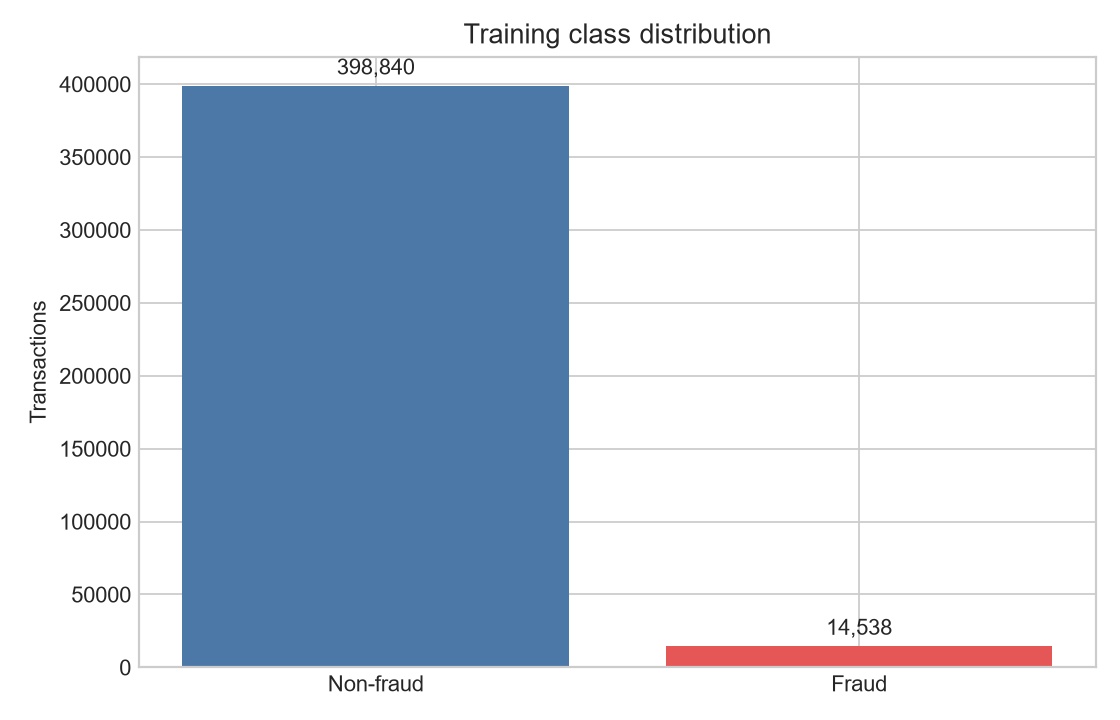

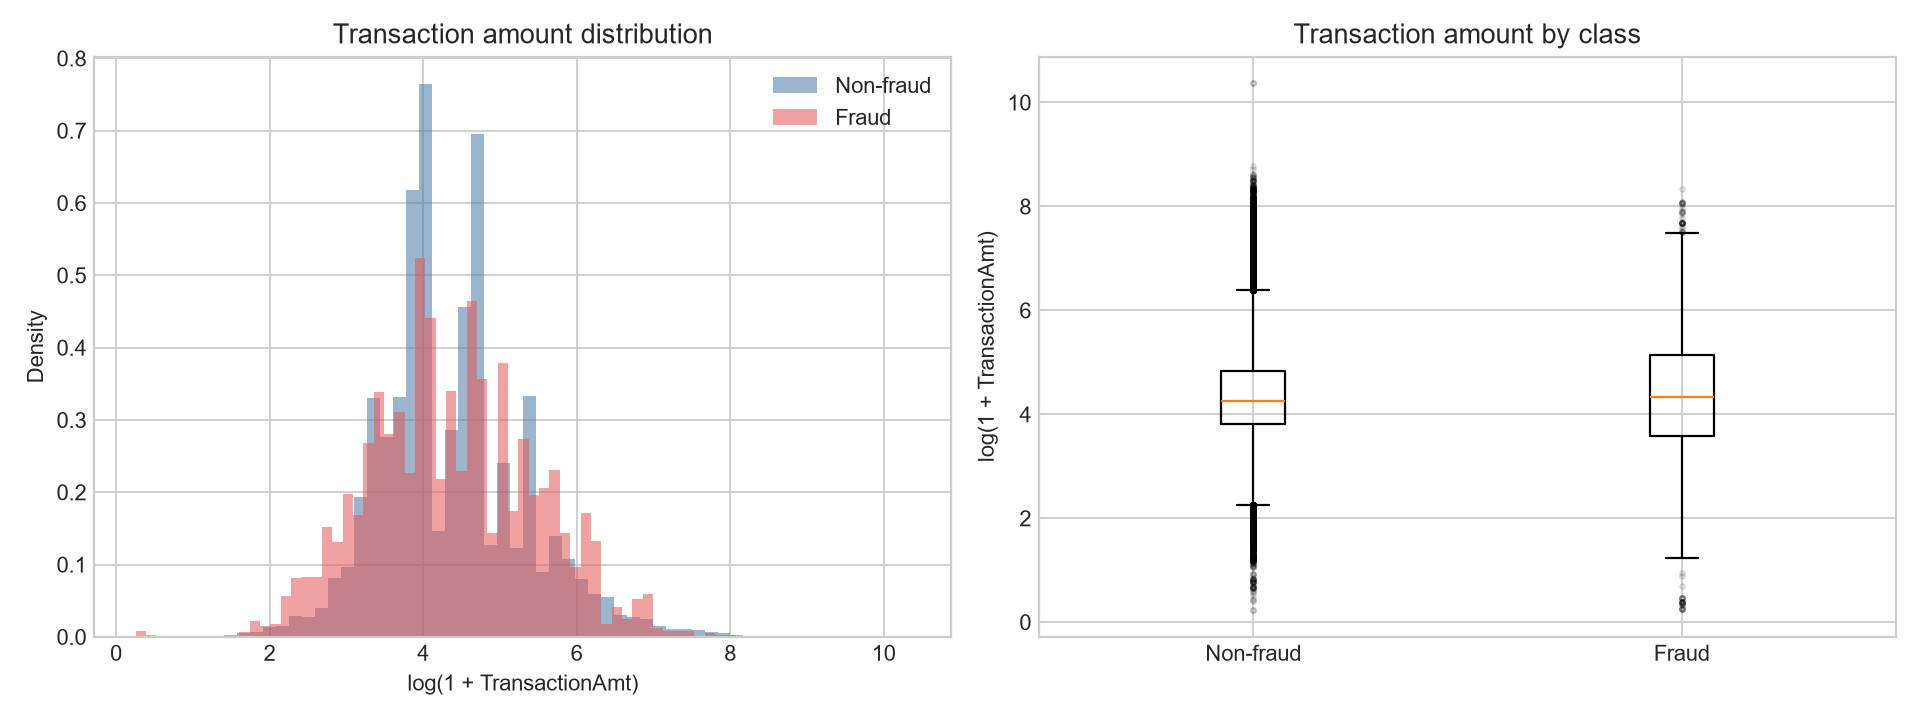

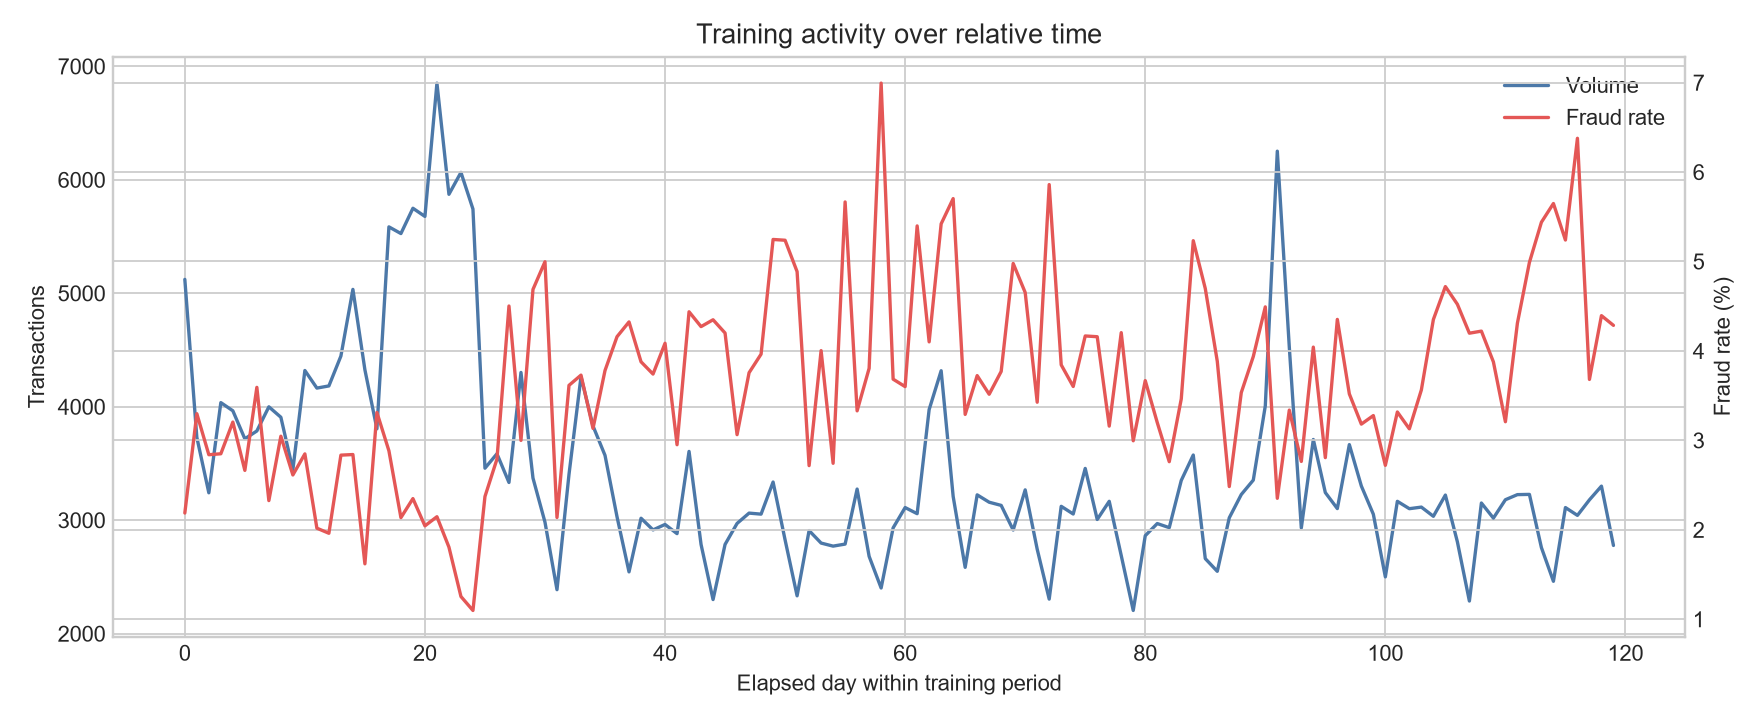

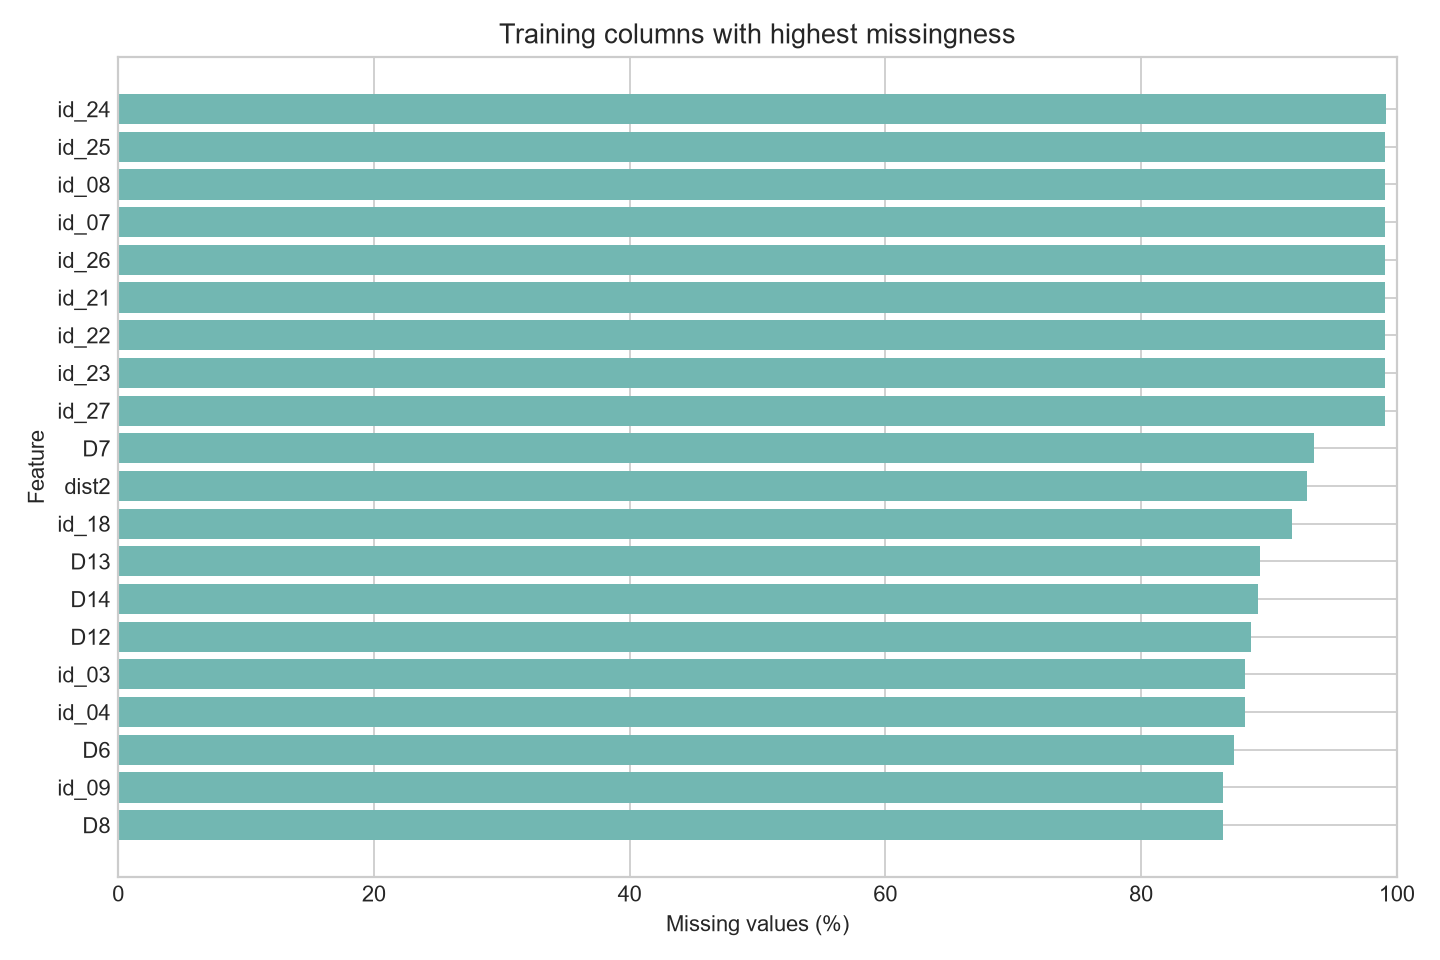

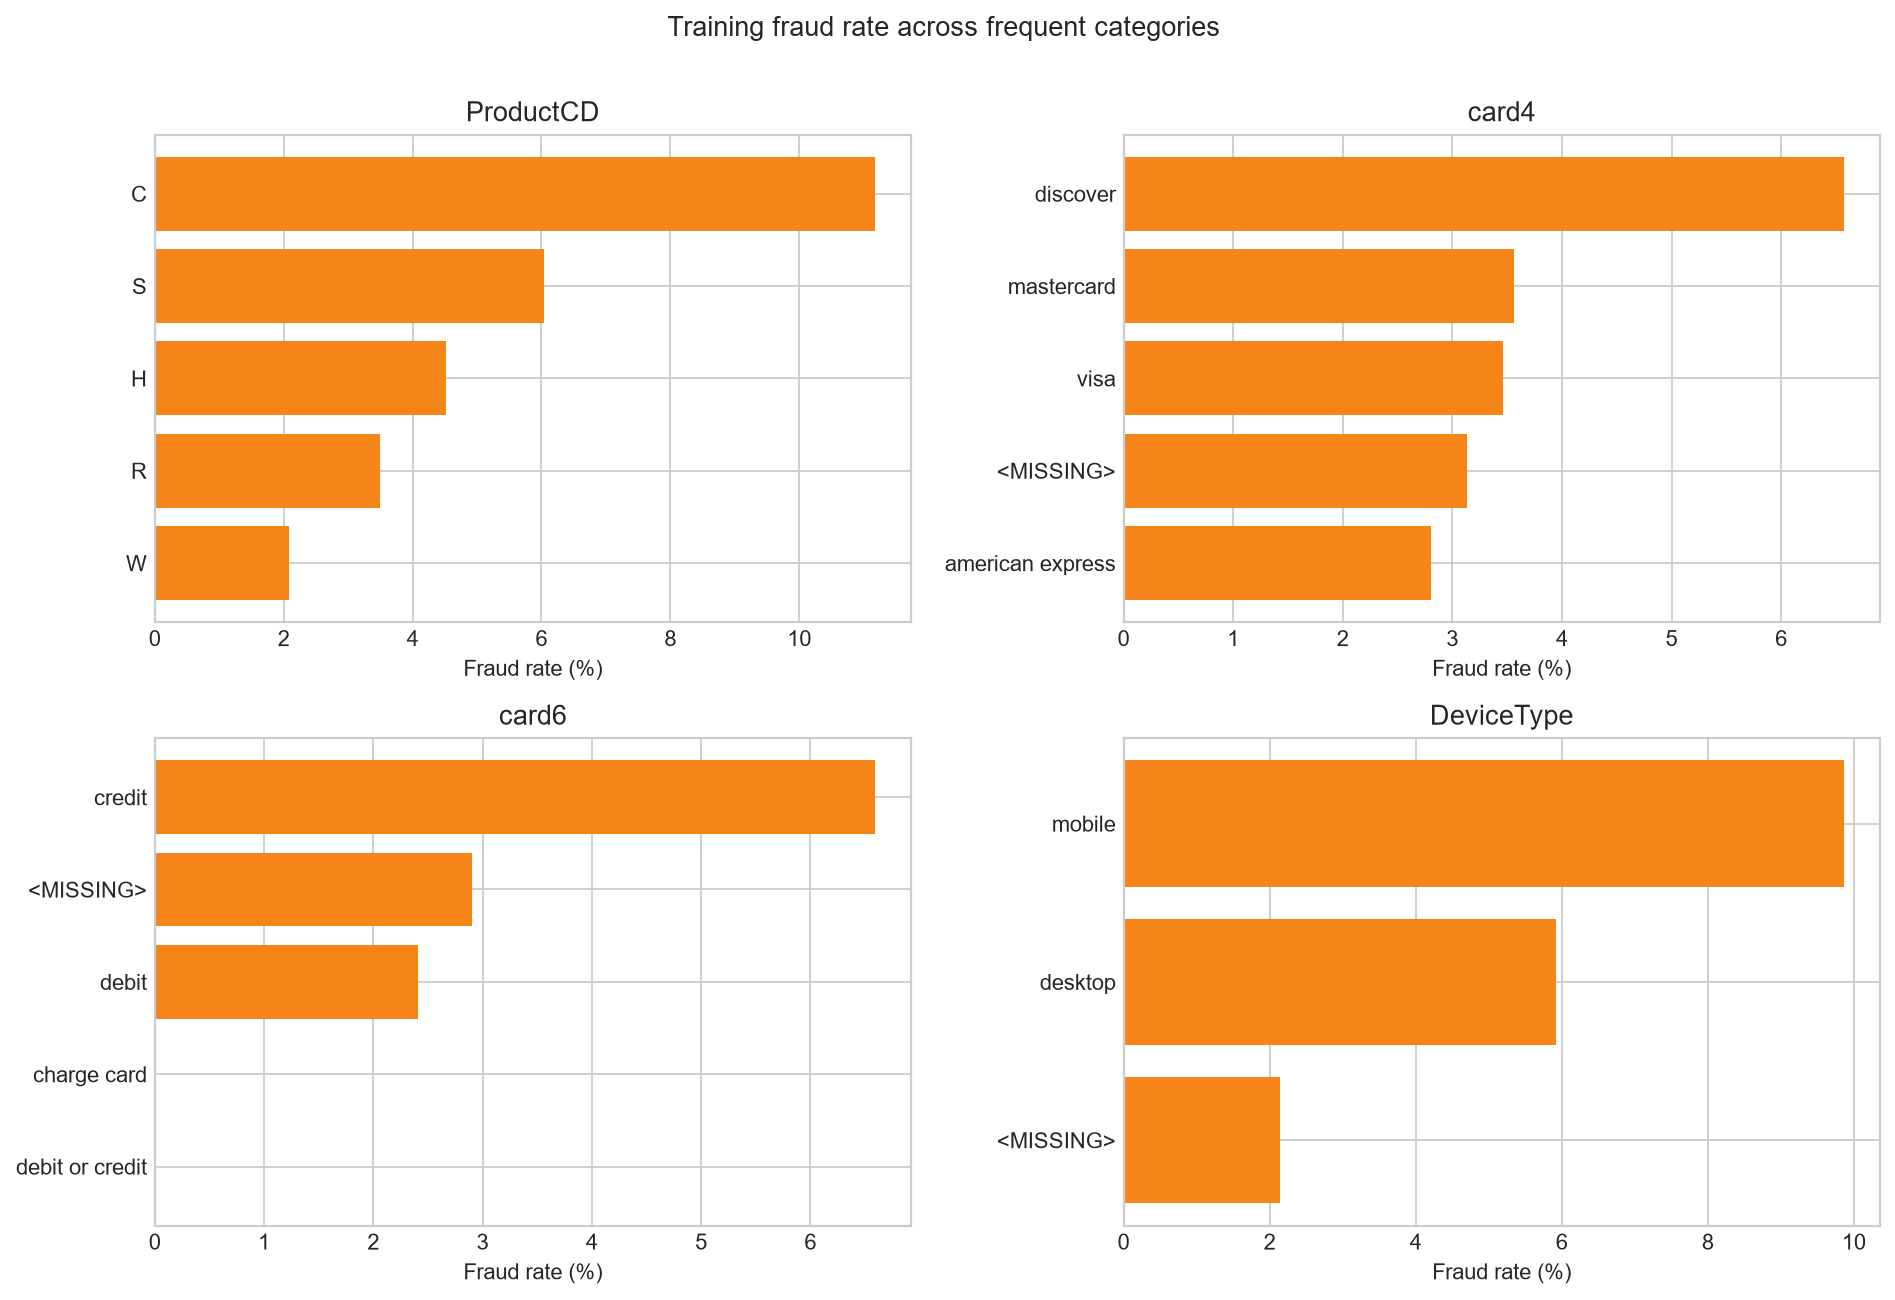

In [11]:
figure_paths = save_eda_plots(train, PROJECT_ROOT / "reports" / "figures")
for path in figure_paths:
    display(Image(filename=str(path)))

## 9. Potential leakage review

- **TransactionID:** likely tracks collection order; review rather than use as a magnitude.
- **TransactionDT:** available at transaction time but can encode changing base rates; evaluation must stay chronological.
- **Anonymized V, D, and identity fields:** definitions and availability timing require provenance review. Strong association alone does not prove leakage.
- **isFraud:** the target and always excluded from predictors.

No non-target feature is declared leaked by this notebook.

## 10. Conclusions

### Observed facts

- Fraud is rare and its rate changes across relative time.
- Transaction amounts are heavily right-skewed.
- Product, payment-card, email, and device groups have materially different training fraud rates.
- Missingness is extensive and sometimes associated with the target.
- Several card/device identifiers are too high-cardinality for naive one-hot encoding.

### Future feature-engineering hypotheses

- Test log amount, missing indicators, frequency encodings, past-only velocity, and entity-relative amount features.
- Explore time-safe card/address/email/device graph features in a later phase.

These are hypotheses only; this notebook does not implement production features.